# Hilbert行列はなぜコンピュータにとって難しいのか

## 概要

Hilbert行列は厳密には逆行列を持つが、微小な入力誤差によって解が大きく変化する。本記事の目的は、有限精度での求解が難しくなる理由を条件数から説明することである。正則性と誤差の評価を導き、Pythonで残差・入力の変化・計算精度を比較する。

## 準備

### 実行環境

仮想環境は `wa-src(3.14.6)`、Pythonは `3.14.6` である。NumPyとSciPyで倍精度計算、mpmathで多倍長計算、Matplotlibで描画を行う。使用したライブラリのバージョンは次のセルに表示する。

### 表示と保存

セルは上から順に実行する。小数は有効数字3桁で表示し、計算途中の値は丸めない。グラフの軸名は英語とし、SVG形式でノートブックに埋め込む。SVGファイルは実行時の作業ディレクトリの `figures` に保存する。

In [1]:
import sys
from pathlib import Path
from pprint import pprint

import matplotlib
import matplotlib.pyplot as plt
import mpmath as mp
import numpy as np
import scipy
from IPython.display import Math, display
from matplotlib.ticker import FuncFormatter, MaxNLocator
from matplotlib_inline.backend_inline import set_matplotlib_formats
from scipy.linalg import hilbert

%matplotlib inline

# 指定したPythonの仮想環境で実行していることを確認する。
assert sys.version_info[:3] == (3, 14, 6)
assert sys.prefix != sys.base_prefix
print(f"実行環境: wa-src({sys.version.split()[0]})")
print(f"NumPy {np.__version__}, SciPy {scipy.__version__}")
print(f"Matplotlib {matplotlib.__version__}, mpmath {mp.__version__}")

# 数値は表示するときだけ有効数字3桁に整える。
# .2eは小数点以下2桁の指数表記であり、有効数字は3桁となる。
np.set_printoptions(formatter={"float_kind": lambda value: f"{value:.2e}"})
tick_formatter = FuncFormatter(lambda value, position: f"{value:#.3g}")

# SVG形式でノートブックに図を埋め込む。
set_matplotlib_formats("svg")
plt.rcParams.update({
    "figure.figsize": (11, 4),
    "figure.dpi": 130,
    "savefig.format": "svg",
    "font.size": 10,
    "axes.grid": True,
    "grid.alpha": 0.250,
})


# 実行時の作業ディレクトリに、SVGの保存先を作る。
figure_dir = Path("figures")
figure_dir.mkdir(parents=True, exist_ok=True)


def scientific_latex(value):
    """数値を有効数字3桁のLaTeX表記に変換する。"""
    mantissa, exponent = f"{float(value):.2e}".split("e")
    return rf"{mantissa}\times 10^{{{int(exponent)}}}"


def make_mp_hilbert(size):
    """現在のmpmathの精度でHilbert行列を生成する。"""
    # 整数をmpmathの数に変換してから割り、倍精度の丸めを避ける。
    # Pythonの添字は0から始まるため、分母はi + j + 1となる。
    return mp.matrix([
        [mp.mpf(1) / (i + j + 1) for j in range(size)]
        for i in range(size)
    ])

実行環境: wa-src(3.14.6)
NumPy 2.5.4, SciPy 1.18.1
Matplotlib 3.11.2, mpmath 1.3.0


## 1-1. Hilbert行列の定義と正則性

### 1. 数式と考え方

添字を1から数えると、定義は次式である。Pythonの添字は0から始まるため、実装では分母が `i + j + 1` となる。[SciPy公式資料](https://docs.scipy.org/doc/scipy/reference/generated/scipy.linalg.hilbert.html)にも同じ定義がある。

$$
\mathbf{H}_n=(h_{ij}),\qquad h_{ij}=\frac{1}{i+j-1},\quad 1\le i,j\le n.
$$

成分は単項式の積の積分でも表せる。

$$
\int_0^1 t^{i-1}t^{j-1}\,dt
=\int_0^1 t^{i+j-2}\,dt
=\left[\frac{t^{i+j-1}}{i+j-1}\right]_0^1
=\frac{1}{i+j-1}.
$$

任意の実ベクトル $\mathbf{c}\ne\mathbf{0}$ に対して、和と積分を入れ替えると、

$$
\begin{aligned}
\mathbf{c}^{\mathsf T}\mathbf{H}_n\mathbf{c}
&=\sum_{i=1}^n\sum_{j=1}^n c_i c_j h_{ij}\\
&=\int_0^1\sum_{i=1}^n\sum_{j=1}^n c_i c_j t^{i-1}t^{j-1}\,dt\\
&=\int_0^1\left(\sum_{i=1}^n c_i t^{i-1}\right)^2dt>0.
\end{aligned}
$$

非零の多項式の二乗の積分は正である。したがって、$\mathbf{H}_n$ は対称正定値であり、正則である。一方、単項式の線形結合では相殺が起こり、係数の大きさに比べて積分値が小さくなり得る。この性質が小さな固有値につながる。

### 2. Pythonによる計算例

In [2]:
# 3次の行列を小数と分数の両方で確認する。
H3 = hilbert(3)
print("Hilbert行列（n = 3、小数表示）")
pprint(H3)

# 数式は文字列としてprintせず、LaTeXとして表示する。
display(
    Math(
        r"\mathbf{H}_3=\begin{bmatrix}"
        r"1 & \frac{1}{2} & \frac{1}{3}\\"
        r"\frac{1}{2} & \frac{1}{3} & \frac{1}{4}\\"
        r"\frac{1}{3} & \frac{1}{4} & \frac{1}{5}"
        r"\end{bmatrix}"
    )
)

Hilbert行列（n = 3、小数表示）
array([[1.00e+00, 5.00e-01, 3.33e-01],
       [5.00e-01, 3.33e-01, 2.50e-01],
       [3.33e-01, 2.50e-01, 2.00e-01]])


<IPython.core.display.Math object>

SVG保存先: figures/01_hilbert_and_monomials.svg


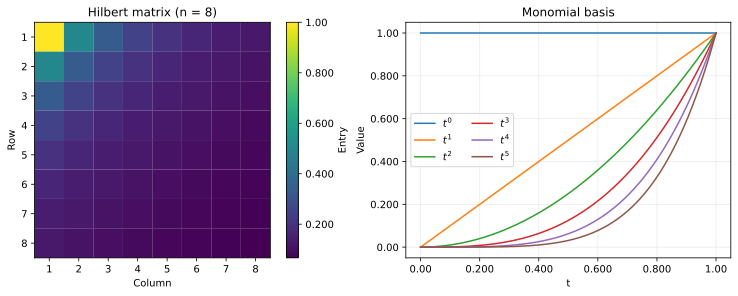

In [3]:
fig, axes = plt.subplots(1, 2, layout="constrained")

# 左図: 成分の値を色で表す。行・列番号は数式と同じ1始まりにする。
# 各成分を四角形で描き、SVG内でもベクトル形式を保つ。
cell_edges = np.arange(9) + 0.500
heatmap = axes[0].pcolormesh(
    cell_edges,
    cell_edges,
    hilbert(8),
    cmap="viridis",
    shading="flat",
    edgecolors="face",
    linewidth=0.100,
)
axes[0].set_aspect("equal")
axes[0].invert_yaxis()
axes[0].grid(False)
axes[0].set(title="Hilbert matrix (n = 8)", xlabel="Column", ylabel="Row")
axes[0].set_xticks(range(1, 9))
axes[0].set_yticks(range(1, 9))
colorbar = fig.colorbar(heatmap, ax=axes[0], format=tick_formatter, label="Entry")
# カラーバーもベクトルとして保存する。
colorbar.solids.set_rasterized(False)
# SVG表示時の色の区切りに、白い継ぎ目が出ることを防ぐ。
colorbar.solids.set_edgecolor("face")

# 右図: 行列の成分を積分で表したときに現れる単項式を描く。
t = np.linspace(0, 1, 300)
for degree in range(6):
    axes[1].plot(t, t**degree, label=rf"$t^{degree}$")

axes[1].set(title="Monomial basis", xlabel="t", ylabel="Value")
axes[1].xaxis.set_major_formatter(tick_formatter)
axes[1].yaxis.set_major_formatter(tick_formatter)
axes[1].legend(ncol=2)
# SVGファイルとして保存し、ノートブックにも表示する。
svg_path = figure_dir / "01_hilbert_and_monomials.svg"
fig.savefig(svg_path, format="svg", bbox_inches="tight")
print(f"SVG保存先: {svg_path.as_posix()}")
plt.show()

## 1-2. 条件数と誤差の増幅

### 1. 数式と考え方

以下ではベクトルのユークリッドノルムと、それに対応する行列の2ノルムを使う。最大・最小特異値を $\sigma_{\max},\sigma_{\min}$ とすると、条件数は

$$
\kappa_2(\mathbf{H})=\|\mathbf{H}\|_2\|\mathbf{H}^{-1}\|_2
=\frac{\sigma_{\max}}{\sigma_{\min}}
$$

である。右辺だけが変化した場合を考える。

$$
\begin{aligned}
\mathbf{H}\mathbf{x}&=\mathbf{b},\\
\mathbf{H}(\mathbf{x}+\Delta\mathbf{x})&=\mathbf{b}+\Delta\mathbf{b},\\
\mathbf{H}\Delta\mathbf{x}&=\Delta\mathbf{b},\\
\Delta\mathbf{x}&=\mathbf{H}^{-1}\Delta\mathbf{b}.
\end{aligned}
$$

ここで $\|\Delta\mathbf{x}\|_2\le\|\mathbf{H}^{-1}\|_2\|\Delta\mathbf{b}\|_2$、かつ $\|\mathbf{b}\|_2\le\|\mathbf{H}\|_2\|\mathbf{x}\|_2$ である。両者を使うと、

$$
\frac{\|\Delta\mathbf{x}\|_2}{\|\mathbf{x}\|_2}
\le\|\mathbf{H}^{-1}\|_2\|\Delta\mathbf{b}\|_2
\frac{\|\mathbf{H}\|_2}{\|\mathbf{b}\|_2}
=\kappa_2(\mathbf{H})\frac{\|\Delta\mathbf{b}\|_2}{\|\mathbf{b}\|_2}.
$$

これは最悪の場合の上限であり、常にこの倍率で誤差が生じるわけではない。次のコードでは、倍精度の特異値分解と、80桁の計算を比較する。正定値行列では固有値と特異値が一致するため、多倍長側は最大・最小固有値の比を使う。

### 2. Pythonによる計算例

In [4]:
matrix_sizes = np.arange(2, 15)
condition_float64 = []
condition_high_precision = []

for size in matrix_sizes:
    size = int(size)

    # 倍精度側は特異値分解を使って2ノルムの条件数を求める。
    condition_float64.append(np.linalg.cond(hilbert(size), 2))

    # 対称正定値行列では最大・最小固有値の比も条件数となる。
    with mp.workdps(80):
        eigenvalues = mp.eigsy(make_mp_hilbert(size), eigvals_only=True)
        condition = eigenvalues[size - 1] / eigenvalues[0]

        # 条件数の計算を終えてから、表示・描画用にfloatへ変換する。
        condition_high_precision.append(float(condition))

condition_float64 = np.array(condition_float64)
condition_high_precision = np.array(condition_high_precision)

# 代表的な次数だけを出力し、数値の変化を読み取りやすくする。
condition_summary = []
for size, value64, value80 in zip(matrix_sizes, condition_float64, condition_high_precision):
    if size in (6, 10, 12, 14):
        condition_summary.append(
            {
                "n": int(size),
                "cond_float64": f"{value64:.2e}",
                "cond_80digits": f"{value80:.2e}",
            }
        )

print("次数ごとの条件数（倍精度と80桁計算）")
pprint(condition_summary, sort_dicts=False)

次数ごとの条件数（倍精度と80桁計算）
[{'n': 6, 'cond_float64': '1.50e+07', 'cond_80digits': '1.50e+07'},
 {'n': 10, 'cond_float64': '1.60e+13', 'cond_80digits': '1.60e+13'},
 {'n': 12, 'cond_float64': '1.72e+16', 'cond_80digits': '1.71e+16'},
 {'n': 14, 'cond_float64': '4.05e+17', 'cond_80digits': '1.85e+19'}]


SVG保存先: figures/02_singular_values_and_condition.svg


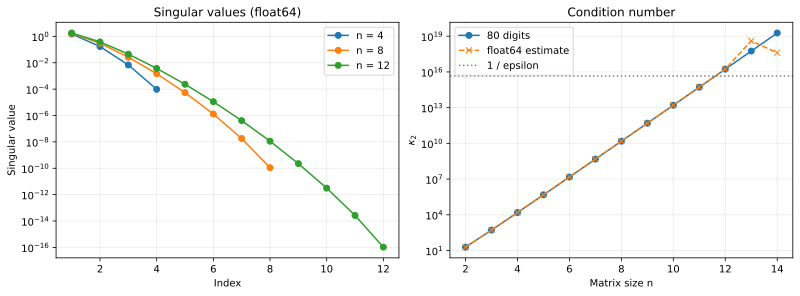

In [5]:
fig, axes = plt.subplots(1, 2, layout="constrained")

# 左図: 小さな特異値まで比較できるように縦軸を対数にする。
for size in (4, 8, 12):
    singular_values = np.linalg.svd(hilbert(size), compute_uv=False)
    indices = np.arange(1, size + 1)
    axes[0].semilogy(indices, singular_values, "o-", label=f"n = {size}")

axes[0].set(
    title="Singular values (float64)",
    xlabel="Index",
    ylabel="Singular value",
)
axes[0].xaxis.set_major_locator(MaxNLocator(integer=True))
axes[0].legend()

# 右図: 同じ次数について、倍精度と多倍長の条件数を比較する。
axes[1].semilogy(matrix_sizes, condition_high_precision, "o-", label="80 digits")
axes[1].semilogy(matrix_sizes, condition_float64, "x--", label="float64 estimate")
axes[1].axhline(
    1 / np.finfo(float).eps,
    color="gray",
    linestyle=":",
    label="1 / epsilon",
)
axes[1].set(title="Condition number", xlabel="Matrix size n", ylabel=r"$\kappa_2$")
axes[1].xaxis.set_major_locator(MaxNLocator(integer=True))
axes[1].legend()
# SVGファイルとして保存し、ノートブックにも表示する。
svg_path = figure_dir / "02_singular_values_and_condition.svg"
fig.savefig(svg_path, format="svg", bbox_inches="tight")
print(f"SVG保存先: {svg_path.as_posix()}")
plt.show()

### 3. 計算結果

$n=14$ の条件数は80桁計算で約 $1.85\times10^{19}$ である。本環境の倍精度計算では約 $4.05\times10^{17}$ となり、条件数自体の評価にも誤差が見られる。

## 1-3. 丸め誤差と小さな残差

### 1. 数式と考え方

`float64` の1と次の数の間隔は $\varepsilon=2^{-52}\approx2.22\times10^{-16}$ である。最近接丸めの単位丸め誤差は $u=\varepsilon/2$ であり、$1/3$ などは格納時点で丸められる。[Highamの解説](https://nhigham.com/2020/06/30/what-is-the-hilbert-matrix/)も、この入力誤差と悪条件性を指摘している。

80桁で求めた $\kappa_2(\mathbf{H}_{12})$ は約 $1.71\times10^{16}$ である。倍精度では解の有効桁を失い得る。さらに大きな行列では、倍精度で求めた条件数自体にも大きな誤差が含まれる。

既知の解を $\mathbf{x}_*=\mathbf{1}$ とし、$\mathbf{b}=\mathbf{H}\mathbf{x}_*$ を作って解く。ただし、コード中では行列の格納と右辺の積にも丸めが入る。得られた解を $\widehat{\mathbf{x}}$ とすると、相対前進誤差と相対残差は次式である。

$$
E=\frac{\|\widehat{\mathbf{x}}-\mathbf{x}_*\|_2}{\|\mathbf{x}_*\|_2},
\qquad R=\frac{\|\mathbf{b}-\mathbf{H}\widehat{\mathbf{x}}\|_2}{\|\mathbf{b}\|_2}.
$$

厳密な方程式の解を $\mathbf{x}$、残差を $\mathbf{r}=\mathbf{b}-\mathbf{H}\widehat{\mathbf{x}}$ とすれば、

$$
\mathbf{r}=\mathbf{H}(\mathbf{x}-\widehat{\mathbf{x}}),\qquad
\widehat{\mathbf{x}}-\mathbf{x}=-\mathbf{H}^{-1}\mathbf{r}.
$$

前節と同じ評価により、相対解誤差は $\kappa_2(\mathbf{H})R$ 以下となる。したがって、小さな残差だけでは解の正確さを判断できない。実験の残差も倍精度で評価する。対数軸では、計算上0となった残差を表示しない。

### 2. Pythonによる計算例

In [6]:
forward_errors = []
relative_residuals = []
computed_solutions = {}

for size in matrix_sizes:
    size = int(size)
    H = hilbert(size)

    # 目標の解を全成分1とし、それに対応する右辺を作る。
    # この行列積にも倍精度の丸めが入る。
    x_true = np.ones(size)
    b = H @ x_true
    x_hat = np.linalg.solve(H, b)

    # 解そのものの誤差と、方程式を満たす程度を別々に評価する。
    forward_error = np.linalg.norm(x_hat - x_true) / np.linalg.norm(x_true)
    relative_residual = np.linalg.norm(b - H @ x_hat) / np.linalg.norm(b)

    forward_errors.append(forward_error)
    relative_residuals.append(relative_residual)
    computed_solutions[size] = x_hat

error_summary = []
for size, error, residual in zip(matrix_sizes, forward_errors, relative_residuals):
    if size in (8, 10, 12, 14):
        error_summary.append(
            {
                "n": int(size),
                "forward_error": f"{error:.2e}",
                "relative_residual": f"{residual:.2e}",
            }
        )

print("相対前進誤差と相対残差")
pprint(error_summary, sort_dicts=False)
display(Math(r"\varepsilon=" + scientific_latex(np.finfo(float).eps)))

相対前進誤差と相対残差
[{'n': 8, 'forward_error': '8.31e-08', 'relative_residual': '1.34e-16'},
 {'n': 10, 'forward_error': '3.81e-04', 'relative_residual': '1.31e-16'},
 {'n': 12, 'forward_error': '1.03e-01', 'relative_residual': '1.09e-16'},
 {'n': 14, 'forward_error': '3.71e+00', 'relative_residual': '1.24e-16'}]


<IPython.core.display.Math object>

SVG保存先: figures/03_errors_and_solutions.svg


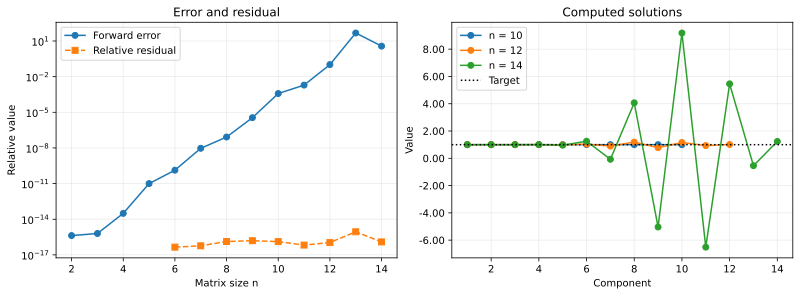

In [7]:
fig, axes = plt.subplots(1, 2, layout="constrained")

# 左図: 計算上0となった残差は対数軸に表示できないため除外する。
# np.nanはグラフの欠測値であり、残差の計算結果は変更しない。
positive_residuals = np.where(
    np.array(relative_residuals) > 0,
    relative_residuals,
    np.nan,
)
axes[0].semilogy(matrix_sizes, forward_errors, "o-", label="Forward error")
axes[0].semilogy(matrix_sizes, positive_residuals, "s--", label="Relative residual")
axes[0].set(
    title="Error and residual",
    xlabel="Matrix size n",
    ylabel="Relative value",
)
axes[0].xaxis.set_major_locator(MaxNLocator(integer=True))
axes[0].legend()

# 右図: 計算された解の各成分を、目標値1と比較する。
for size in (10, 12, 14):
    indices = np.arange(1, size + 1)
    axes[1].plot(indices, computed_solutions[size], "o-", label=f"n = {size}")

axes[1].axhline(1, color="black", linestyle=":", label="Target")
axes[1].set(title="Computed solutions", xlabel="Component", ylabel="Value")
axes[1].xaxis.set_major_locator(MaxNLocator(integer=True))
axes[1].yaxis.set_major_formatter(tick_formatter)
axes[1].legend()
# SVGファイルとして保存し、ノートブックにも表示する。
svg_path = figure_dir / "03_errors_and_solutions.svg"
fig.savefig(svg_path, format="svg", bbox_inches="tight")
print(f"SVG保存先: {svg_path.as_posix()}")
plt.show()

### 3. 計算結果

本環境の $n=12$ では相対残差が $1.09\times10^{-16}$ である一方、相対前進誤差は $1.03\times10^{-1}$ である。残差が丸め誤差程度でも、目標の解からのずれは小さくない。

## 1-4. 小さな入力変化を加える

### 1. 数式と考え方

特異値分解の単位ベクトルが $\mathbf{H}\mathbf{v}_i=\sigma_i\mathbf{u}_i$ を満たすことを使う。$\mathbf{x}=\mathbf{v}_{\max}$、$\mathbf{b}=\sigma_{\max}\mathbf{u}_{\max}$ とし、$\Delta\mathbf{b}=\delta\sigma_{\max}\mathbf{u}_{\min}$ を加えると、

$$
\Delta\mathbf{x}
=\mathbf{H}^{-1}\Delta\mathbf{b}
=\frac{\delta\sigma_{\max}}{\sigma_{\min}}\mathbf{v}_{\min},\qquad
\frac{\|\Delta\mathbf{x}\|_2}{\|\mathbf{x}\|_2}=\delta\kappa_2(\mathbf{H}).
$$

この方向では上限に達する。$n=8$ で、入力変化と解の変化を比較する。元の解との差を取っても計算誤差は残るため、極小の入力変化では理論値から外れ得る。

### 2. Pythonによる計算例

In [8]:
H = hilbert(8)
U, singular_values, Vt = np.linalg.svd(H)

# 最大特異値に対応する右特異ベクトルを元の解に選ぶ。
x_original = Vt[0]
b_original = H @ x_original
x_baseline = np.linalg.solve(H, b_original)

perturbation_sizes = np.logspace(-14, -8, 13)
relative_changes = []

for delta in perturbation_sizes:
    # 最小特異値に対応する左特異ベクトル方向へ右辺を変化させる。
    # 変化のノルムは、元の右辺のノルムのdelta倍とする。
    delta_b = delta * np.linalg.norm(b_original) * U[:, -1]
    x_shifted = np.linalg.solve(H, b_original + delta_b)

    relative_change = np.linalg.norm(x_shifted - x_baseline) / np.linalg.norm(x_baseline)
    relative_changes.append(relative_change)

condition_number = singular_values[0] / singular_values[-1]
theoretical_changes = condition_number * perturbation_sizes

# 数表でも理論値との一致を確認する。
perturbation_summary = []
for index in (0, 6, 12):
    perturbation_summary.append(
        {
            "input_change": f"{perturbation_sizes[index]:.2e}",
            "solution_change": f"{relative_changes[index]:.2e}",
            "theory": f"{theoretical_changes[index]:.2e}",
        }
    )

print("入力の相対変化と解の相対変化")
pprint(perturbation_summary, sort_dicts=False)

入力の相対変化と解の相対変化
[{'input_change': '1.00e-14',
  'solution_change': '1.52e-04',
  'theory': '1.53e-04'},
 {'input_change': '1.00e-11',
  'solution_change': '1.53e-01',
  'theory': '1.53e-01'},
 {'input_change': '1.00e-08',
  'solution_change': '1.53e+02',
  'theory': '1.53e+02'}]


SVG保存先: figures/04_perturbation_amplification.svg


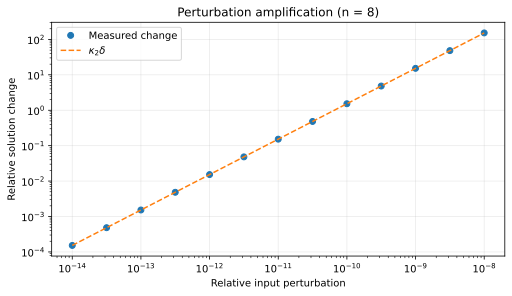

In [9]:
# 両対数軸で、実測した変化と条件数による理論値を比較する。
fig, ax = plt.subplots(figsize=(7, 4), layout="constrained")
ax.loglog(perturbation_sizes, relative_changes, "o", label="Measured change")
ax.loglog(
    perturbation_sizes,
    theoretical_changes,
    "--",
    label=r"$\kappa_2\delta$",
)
ax.set(
    title="Perturbation amplification (n = 8)",
    xlabel="Relative input perturbation",
    ylabel="Relative solution change",
)
ax.legend()
# SVGファイルとして保存し、ノートブックにも表示する。
svg_path = figure_dir / "04_perturbation_amplification.svg"
fig.savefig(svg_path, format="svg", bbox_inches="tight")
print(f"SVG保存先: {svg_path.as_posix()}")
plt.show()

## 1-5. 精度を上げる場合の注意

### 1. 数式と考え方

`solve` は逆行列を明示的に作らずに連立方程式を解くが、問題の条件数は変えない。多倍長計算では、整数から分数を作り直す必要がある。丸め済みの行列と右辺を高精度に変換しても、元の入力情報は戻らない。

次の比較では $n=12$ を固定する。一方は各精度で行列と右辺を作り直し、他方は倍精度で作った入力をそのまま多倍長に変換する。どちらも $\mathbf{1}$ からの誤差を測る。後者が正確に解く対象は、丸められた別の方程式である。

### 2. Pythonによる計算例

In [10]:
size = 12
H_float64 = hilbert(size)
b_float64 = H_float64 @ np.ones(size)

working_digits = [20, 30, 50, 80]
rebuilt_input_errors = []
rounded_input_errors = []

for digits in working_digits:
    with mp.workdps(digits):
        x_true = mp.matrix([1] * size)

        # 方法1: 行列と右辺を、その時点の多倍長精度で作り直す。
        H_rebuilt = make_mp_hilbert(size)
        b_rebuilt = H_rebuilt * x_true
        x_rebuilt = mp.lu_solve(H_rebuilt, b_rebuilt)

        # 方法2: 倍精度で丸められた入力を、そのまま多倍長へ変換する。
        # 計算精度を増やしても、入力時に失った情報は復元されない。
        H_rounded = mp.matrix(H_float64.tolist())
        b_rounded = mp.matrix(b_float64.tolist())
        x_rounded = mp.lu_solve(H_rounded, b_rounded)

        # 誤差も多倍長で評価し、最後に表示・描画用のfloatへ変換する。
        rebuilt_error = mp.norm(x_rebuilt - x_true) / mp.norm(x_true)
        rounded_error = mp.norm(x_rounded - x_true) / mp.norm(x_true)
        rebuilt_input_errors.append(float(rebuilt_error))
        rounded_input_errors.append(float(rounded_error))

precision_summary = []
for digits, rebuilt_error, rounded_error in zip(working_digits, rebuilt_input_errors, rounded_input_errors):
    precision_summary.append(
        {
            "digits": digits,
            "rebuilt_input_error": f"{rebuilt_error:.2e}",
            "float64_input_error": f"{rounded_error:.2e}",
        }
    )

print("入力の作り方と計算精度による相対前進誤差の比較")
pprint(precision_summary, sort_dicts=False)

入力の作り方と計算精度による相対前進誤差の比較
[{'digits': 20,
  'rebuilt_input_error': '3.15e-07',
  'float64_input_error': '2.11e-01'},
 {'digits': 30,
  'rebuilt_input_error': '8.44e-17',
  'float64_input_error': '2.11e-01'},
 {'digits': 50,
  'rebuilt_input_error': '7.19e-37',
  'float64_input_error': '2.11e-01'},
 {'digits': 80,
  'rebuilt_input_error': '1.23e-66',
  'float64_input_error': '2.11e-01'}]


SVG保存先: figures/05_precision_and_input_accuracy.svg


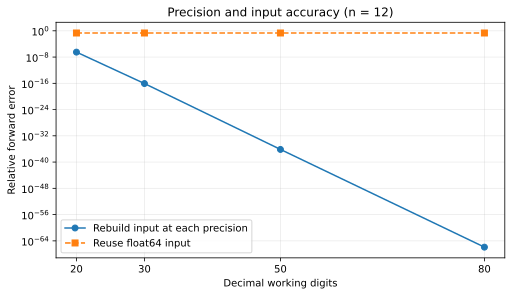

In [11]:
# 多倍長の計算桁数と、目標の解からのずれを比較する。
fig, ax = plt.subplots(figsize=(7, 4), layout="constrained")
ax.semilogy(
    working_digits,
    rebuilt_input_errors,
    "o-",
    label="Rebuild input at each precision",
)
ax.semilogy(
    working_digits,
    rounded_input_errors,
    "s--",
    label="Reuse float64 input",
)
ax.set(
    title="Precision and input accuracy (n = 12)",
    xlabel="Decimal working digits",
    ylabel="Relative forward error",
)
ax.set_xticks(working_digits)
ax.legend()
# SVGファイルとして保存し、ノートブックにも表示する。
svg_path = figure_dir / "05_precision_and_input_accuracy.svg"
fig.savefig(svg_path, format="svg", bbox_inches="tight")
print(f"SVG保存先: {svg_path.as_posix()}")
plt.show()

### 3. 計算結果

80桁計算で入力を作り直した場合の誤差は約 $1.23\times10^{-66}$ である。倍精度の入力を使う場合は約 $2.11\times10^{-1}$ であり、計算桁数を増やしてもこのずれは残る。

## 結論

この記事では、Hilbert行列の大きな条件数が入力と計算の微小な誤差を増幅し、倍精度での求解を難しくすることを示した。

厳密な正則性と有限精度での計算精度は別である。残差と条件数を併せて調べ、必要なら入力の生成から精度を上げる。多項式近似で生じる場合には、直交基底への変更も検討対象となる。数値結果の末尾は計算ライブラリにより異なり得る。

参考文献：[NumPyの条件数の定義](https://numpy.org/doc/stable/reference/generated/numpy.linalg.cond.html)。